In [148]:
import   cv2
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


### Question 1 Counting objects

In [2]:
image = cv2.imread("q1_data/1a.png")
image[:1]

array([[[156, 156, 150],
        [152, 152, 146],
        [153, 153, 147],
        ...,
        [218, 205, 185],
        [206, 206, 195],
        [157, 157, 146]]], dtype=uint8)

In [3]:
cv2.imshow("q1_data/1a.png",image)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [4]:
gray_scale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray_scale

array([[154, 150, 151, ..., 201, 203, 154],
       [153, 151, 152, ..., 194, 194, 152],
       [152, 152, 154, ..., 195, 192, 152],
       ...,
       [139, 138, 138, ..., 167, 167, 140],
       [139, 139, 139, ..., 169, 167, 139],
       [139, 139, 139, ..., 162, 150,  80]], dtype=uint8)

In [5]:
blur = cv2.GaussianBlur(gray_scale,(5,5),0)
blur

array([[152, 152, 152, ..., 195, 186, 180],
       [152, 152, 152, ..., 194, 185, 180],
       [152, 152, 153, ..., 193, 184, 179],
       ...,
       [139, 138, 138, ..., 165, 159, 155],
       [139, 139, 139, ..., 163, 154, 149],
       [139, 139, 139, ..., 162, 152, 145]], dtype=uint8)

In [6]:
edges = cv2.Canny(blur,50,150)
edges

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [7]:
contour,_ = cv2.findContours(edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
len(contour)

7

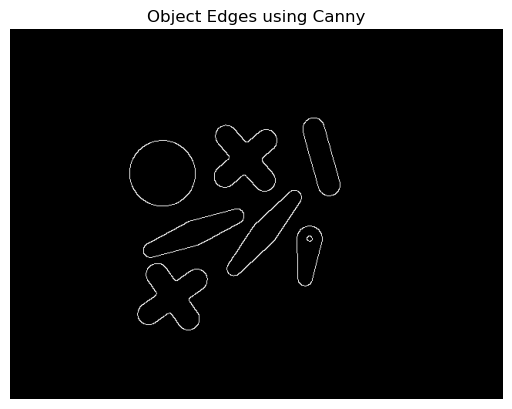

In [8]:
plt.imshow(edges, cmap="gray")
plt.title("Object Edges using Canny")
plt.axis("off")
plt.savefig("canny")
plt.show()

In [9]:
## Sample images  in Data directory
def count_objects(image_path):
    # Load the image using opencv
    image = cv2.imread(image_path)
    # Convert the image to grayscale for easy manipulation
    gray_scale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Apply GaussianBlur to reduce noise and help contour detection
    blur = cv2.GaussianBlur(gray_scale,(5,5),0)
    # Use Canny edge detection we could also use sobel
    edges = cv2.Canny(blur,50,200)
    # Find contours in the edges, this can help to detect the edges 
    contour,_ = cv2.findContours(edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    # Count the number of objects which should just be the number of contours you have i
    
    return len(contour) # return the number of objects

In [10]:
count_objects("q1_data/1a.png") # getting correct for the first image 

7

In [11]:
count_objects("q1_data/1b.png") # not quite getting the right count of the second image b with objects touch each other 

10

In [12]:
image_2 = cv2.imread("q1_data/1b.png")
image_2[:1]

array([[[149, 149, 143],
        [149, 149, 143],
        [149, 149, 143],
        ...,
        [212, 199, 177],
        [198, 199, 190],
        [150, 151, 142]]], dtype=uint8)

In [13]:
gray = cv2.cvtColor(image_2,cv2.COLOR_BGR2GRAY)
gray

array([[147, 147, 147, ..., 194, 196, 148],
       [147, 147, 147, ..., 195, 195, 148],
       [147, 147, 147, ..., 195, 190, 148],
       ...,
       [138, 138, 138, ..., 166, 162, 138],
       [138, 139, 138, ..., 167, 162, 138],
       [137, 138, 138, ..., 166, 150,  80]], dtype=uint8)

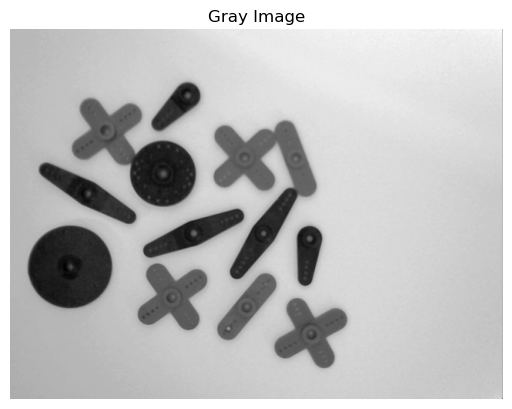

In [14]:
plt.imshow(gray, cmap="gray")
plt.title("Gray Image")
plt.axis("off")
plt.savefig("Gray_image")
plt.show()

In [15]:
blur = cv2.GaussianBlur(gray,(9,9),0)
blur # now from here we start morpological operations 

array([[147, 147, 147, ..., 190, 185, 184],
       [147, 147, 147, ..., 190, 186, 184],
       [147, 147, 147, ..., 190, 186, 184],
       ...,
       [138, 138, 138, ..., 161, 157, 156],
       [138, 138, 138, ..., 160, 156, 154],
       [138, 138, 138, ..., 160, 156, 154]], dtype=uint8)

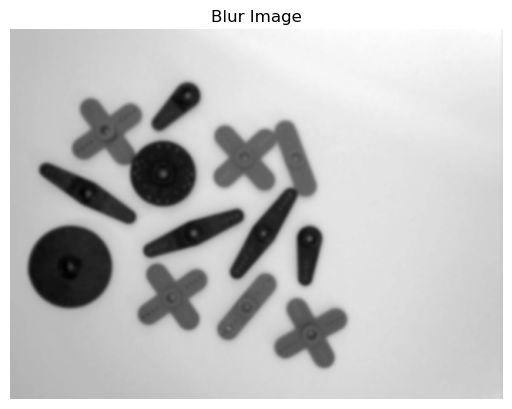

In [16]:
plt.imshow(blur, cmap="gray")
plt.title("Blur Image")
plt.axis("off")
plt.savefig("gausian_blur")
plt.show()

In [17]:
_, binary = cv2.threshold(blur, 200,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU) #thresholding beats edge detection if background is white
binary

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], dtype=uint8)

In [18]:
binary = cv2.bitwise_not(binary) #ensure that objects are white 

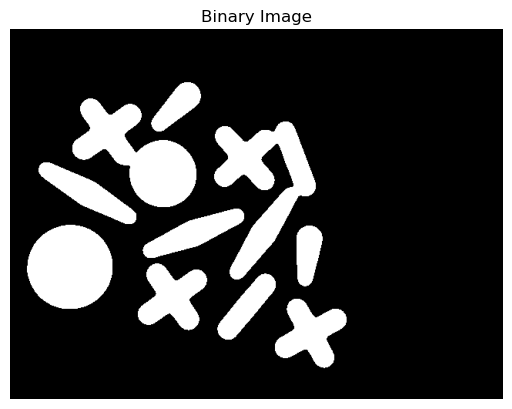

In [19]:
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.savefig("binary")
plt.show()

In [20]:
#lets remove noise 
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(3,3)) #3x3 kernel filter
opening = cv2.morphologyEx(binary,cv2.MORPH_OPEN,kernel,iterations=5)
opening 

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

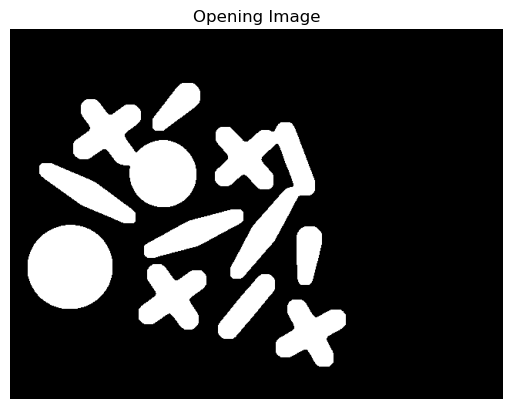

In [21]:
plt.imshow(opening, cmap="gray")
plt.title("Opening Image")
plt.axis("off")
plt.savefig("opening")
plt.show()

In [22]:
closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel, iterations=1)  #hole filling 
#touching object often have internal holes 

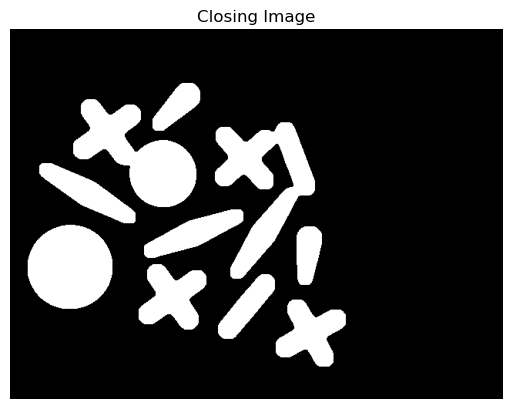

In [23]:
plt.imshow(closing, cmap="gray")
plt.title("Closing Image")
plt.axis("off")
plt.savefig("closing")
plt.show()

In [24]:
dist = cv2.distanceTransform(closing, cv2.DIST_L2, 5) #find the distance of each object even when touching 

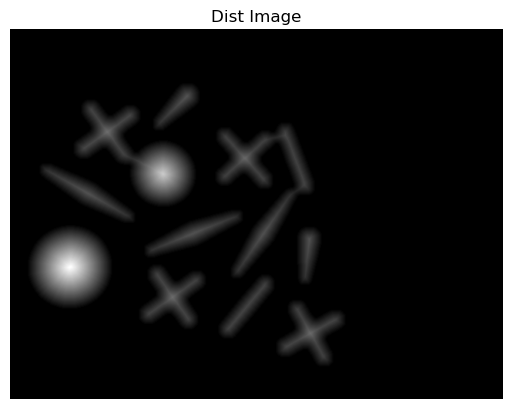

In [25]:
plt.imshow(dist, cmap="gray")
plt.title("Dist Image")
plt.axis("off")
plt.savefig("dist")
plt.show()

In [26]:
_, sure_fg = cv2.threshold(dist, 0.2 * dist.max(), 255, 0) #Sure foreground breaks the watershed 
sure_fg = sure_fg.astype("uint8")

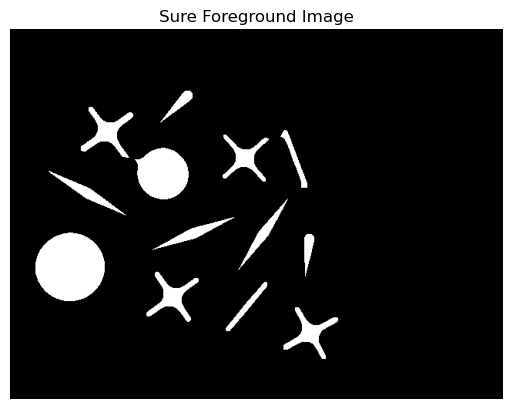

In [27]:
plt.imshow(sure_fg, cmap="gray")
plt.title("Sure Foreground Image")
plt.axis("off")
plt.savefig("sure_fg")
plt.show()

In [28]:
sure_bg = cv2.dilate(closing, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

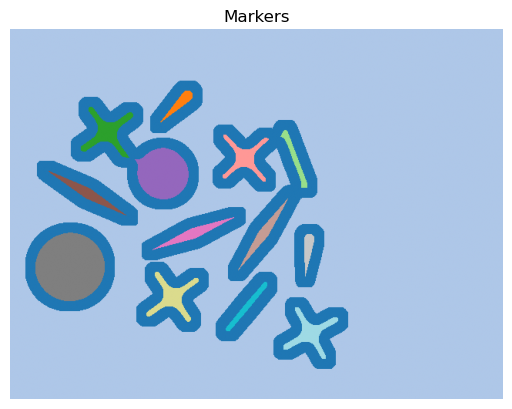

In [29]:
plt.imshow(markers, cmap="tab20")
plt.title("Markers")
plt.axis("off")
plt.savefig("markers")
plt.savefig("markers")
plt.show()


In [30]:
markers = cv2.watershed(image_2,markers)

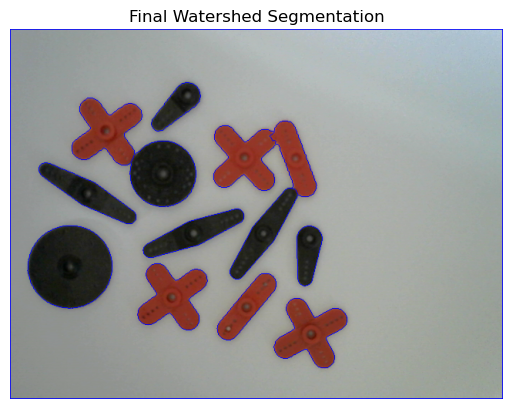

In [31]:
ws = image_2.copy()
ws[markers == -1] = [255, 0, 0]  # red boundaries
ws = cv2.cvtColor(ws, cv2.COLOR_BGR2RGB)

plt.imshow(ws)
plt.title("Final Watershed Segmentation")
plt.axis("off")
plt.savefig("watershed_seg")
plt.show()


In [32]:
labels = set(markers.flatten())
labels.discard(-1)  # boundary
labels.discard(1)   # background

print("Object count:", len(labels))

Object count: 13


### Final Count Object Algorithm

In [33]:
def count_objects(image_path):
    # Load the image using opencv
    image = cv2.imread(image_path)
    # Convert the image to grayscale for easy manipulation
    gray_scale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Apply GaussianBlur to reduce noise and help contour detection
    blur = cv2.GaussianBlur(gray_scale,(9,9),0)
    _, binary = cv2.threshold(blur, 200,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU) #thresholding beats edge detection if background is white
    binary = cv2.bitwise_not(binary) #ensure that objects are white 
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(3,3)) #3x3 kernel filter
    opening = cv2.morphologyEx(binary,cv2.MORPH_OPEN,kernel,iterations=5)
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel, iterations=1)  #hole filling 
    dist = cv2.distanceTransform(closing, cv2.DIST_L2, 5) #find the distance of each object even when touching 
    _, sure_fg = cv2.threshold(dist, 0.2 * dist.max(), 255, 0) #Sure foreground breaks the watershed 
    sure_fg = sure_fg.astype("uint8") #convert to uint8
    sure_bg = cv2.dilate(closing, kernel, iterations=3)
    unknown = cv2.subtract(sure_bg, sure_fg)
    
    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    markers = cv2.watershed(image,markers)

    labels = set(markers.flatten())
    labels.discard(-1)  # boundary
    labels.discard(1)   # background
    
    return len(labels) , markers# return the number of objects

In [34]:
print("Object count:", count_objects("q1_data/1a.png")[0])

Object count: 7


In [35]:
print("Object count:", count_objects("q1_data/1b.png")[0])

Object count: 13


In [36]:
experiment_image = cv2.imread("experiment.png")
experiment_gray = cv2.cvtColor(experiment_image,cv2.COLOR_BGR2GRAY)

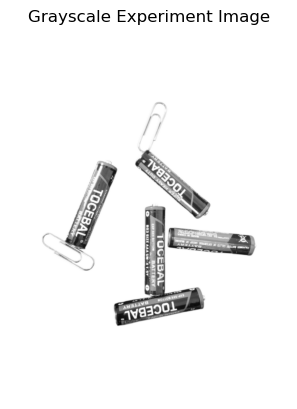

In [37]:
plt.imshow(experiment_gray, cmap="gray")
plt.title("Grayscale Experiment Image")
plt.axis("off")
plt.savefig("experiment_gray")
plt.show()


In [38]:
print("Object count:", count_objects("experiment.png")[0]) # fails significantly if there are words on the objects being counted 

Object count: 39


# Evaluating Image-Based Object Counting on Video

In [39]:
# lets adapt our algorithm 
def count_objects_in_video(image):
    # Load the image using opencv
    # image = cv2.imread(image_path)
    # Convert the image to grayscale for easy manipulation
    gray_scale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Apply GaussianBlur to reduce noise and help contour detection
    blur = cv2.GaussianBlur(gray_scale,(9,9),0)
    _, binary = cv2.threshold(blur, 200,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU) #thresholding beats edge detection if background is white
    binary = cv2.bitwise_not(binary) #ensure that objects are white 
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(3,3)) #3x3 kernel filter
    opening = cv2.morphologyEx(binary,cv2.MORPH_OPEN,kernel,iterations=5)
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel, iterations=1)  #hole filling 
    dist = cv2.distanceTransform(closing, cv2.DIST_L2, 5) #find the distance of each object even when touching 
    _, sure_fg = cv2.threshold(dist, 0.2 * dist.max(), 255, 0) #Sure foreground breaks the watershed 
    sure_fg = sure_fg.astype("uint8") #convert to uint8
    sure_bg = cv2.dilate(closing, kernel, iterations=3)
    unknown = cv2.subtract(sure_bg, sure_fg)
    
    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    markers = cv2.watershed(image,markers)

    labels = set(markers.flatten())
    labels.discard(-1)  # boundary
    labels.discard(1)   # background
    
    return len(labels) , markers# return the number of objects


In [40]:
## Sample images  in Data directory
def count_objects_in_video(image):
    # Load the image using opencv
    # image = cv2.imread(image_path)
    # Convert the image to grayscale for easy manipulation
    gray_scale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Apply GaussianBlur to reduce noise and help contour detection
    blur = cv2.GaussianBlur(gray_scale,(9,9),0)
    # Use Canny edge detection we could also use sobel
    edges = cv2.Canny(blur,50,200)
    # Find contours in the edges, this can help to detect the edges 
    contour,_ = cv2.findContours(edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    # Count the number of objects which should just be the number of contours you have i
    
    return len(contour),contour # return the number of objects

In [41]:
video = cv2.VideoCapture("Computer vision.mp4")

In [42]:
if not video.isOpened():
    print("Error: Could not open video.")

In [43]:
# Prepare to write output video
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter("processed_video_canny_1.mp4", fourcc, 20.0, 
                      (int(video.get(3)), int(video.get(4))))

In [44]:
#Processing 
while True:
    ret,frame = video.read()

    if not ret:
        break 

    count,markers = count_objects_in_video(frame)

    
    # Draw boundaries (optional)
    frame[markers == -1] = [0,0,255]  # red boundaries for watershed
    
    # Overlay count
    cv2.putText(frame, f"Count: {count}", (30,50),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)
    
    out.write(frame)

     # live display of processed video
    cv2.imshow("Processed", frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

video.release()
out.release()
cv2.destroyAllWindows()

### Question 2 Image Straightening 

In [45]:
board_image = cv2.imread("q2_data/2b.jpg")

gray_b = cv2.cvtColor(board_image,cv2.COLOR_BGR2GRAY)
plot_orig = cv2.cvtColor(board_image,cv2.COLOR_BGR2RGB)

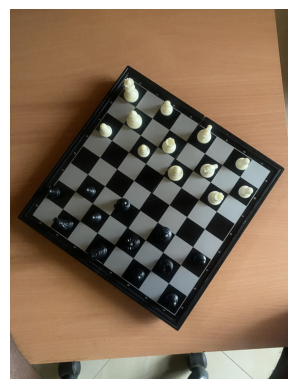

In [46]:
plt.imshow(plot_orig, cmap="gray")
plt.axis("off")
plt.show()

In [47]:
blur_b = cv2.GaussianBlur(gray_b,(5,5,),0)

In [48]:
clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))
enhanced = clahe.apply(blur_b) #CLAHE, enhances constrast locally

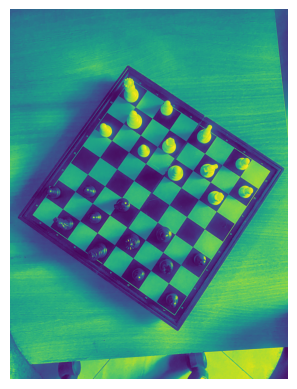

In [49]:
plt.imshow(enhanced)
plt.axis("off")
plt.show()

In [50]:
edge = cv2.Canny(enhanced,50,150)

plt.imshow(edge)
plt.axis("off")
plt.show()

# Canny Approach 

In [52]:
import cv2
import numpy as np

def find_lines(image_path):
    # Load the image using opencv
    img = cv2.imread(image_path)

    # Convert the img to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
   
    # Preprocessing Steps
    # Apply Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    # blurred = cv2.GaussianBlur(gray, (3, 3), 0)  # Experiment: smaller kernel
    # blurred = cv2.GaussianBlur(gray, (7, 7), 0)  # Experiment: stronger smoothing

    # Contrast Enhancement using CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(blurred)
    # clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))  # Experiment: stronger contrast
    # enhanced = clahe.apply(gray)  # Experiment: apply CLAHE before blurring

    # Apply Canny Edge Detection
    edges = cv2.Canny(enhanced, 50, 150)
    # edges = cv2.Canny(enhanced, 30, 100)  # Experiment: more sensitive edges
    # edges = cv2.Canny(enhanced, 100, 200) # Experiment: stricter edge detection

    #Optional to enhance the edges using morphological operations. Should be applied with care
    # Apply Morphological Operations (Dilation + Erosion)
    # kernel = np.ones((3,3), np.uint8)
    # dilated = cv2.dilate(edges, kernel, iterations=1)
    # eroded = cv2.erode(dilated, kernel, iterations=1)
    # edges = eroded  # Use this only if edges are fragmented

    # Apply Hough Transform to detect lines
    # This returns an array of r and theta values
    lines = cv2.HoughLines(edges, 1, np.pi/180, 250)
    # lines = cv2.HoughLines(edges, 1, np.pi/180, 120)  # Experiment: lower threshold
    # lines = cv2.HoughLines(edges, 1, np.pi/360, 150)  # Experiment: finer angle resolution

    # The below for loop runs till r and theta values
    # are in the range of the 2d array
    angles_count = {}

    if lines is not None:
        for r_theta in lines:
            arr = np.array(r_theta[0], dtype=np.float64)
            
            r, theta = arr

            #Convert Polar Coordinates to Cartesian Coordinates
            a = np.cos(theta)
            b = np.sin(theta)
            x0 = a*r
            y0 = b*r

            #Store the angles in a dictionary to count the number of lines corresponding to that angle
            theta_deg = round(theta * 180 / np.pi)  # Rounded for stability

            if theta_deg in angles_count.keys():
                angles_count[theta_deg] += 1
            else:
                angles_count[theta_deg] = 1

            # Second point needed to draw the line
            x1 = int(x0 + 1000*(-b))
            y1 = int(y0 + 1000*(a))

            x2 = int(x0 - 1000*(-b))
            y2 = int(y0 - 1000*(a))

            # Draw the line on the image
            cv2.line(img, (x1, y1), (x2, y2), (0, 0, 255), 2)

    cv2.imwrite('linesDetected.jpg', img)

    # return the angles_count dictionary
    return angles_count


angles_count = find_lines('q2_data/2b.jpg')
top_3_angles = sorted(angles_count, key=angles_count.get, reverse=True)[:3]
img = cv2.imread('linesDetected.jpg')

print("Top 3 dominant angles (degrees):", top_3_angles)


Top 3 dominant angles (degrees): [34, 35, 36]


In [53]:
# convert top angle go degrees for rotation
angle = top_3_angles[0] -270
angle

-236

In [54]:
def plot(img_rgb,hough_rgb,image_name):
    plt.figure(figsize=(12,6))

    plt.subplot(1,2,1)
    plt.imshow(img_rgb)
    plt.title("Original Image")
    plt.axis("off")
    
    plt.subplot(1,2,2)
    plt.imshow(hough_rgb)
    plt.title("Hough Line Transform")
    plt.axis("off")
    
    plt.tight_layout()
    plt.savefig(image_name)
    plt.show()

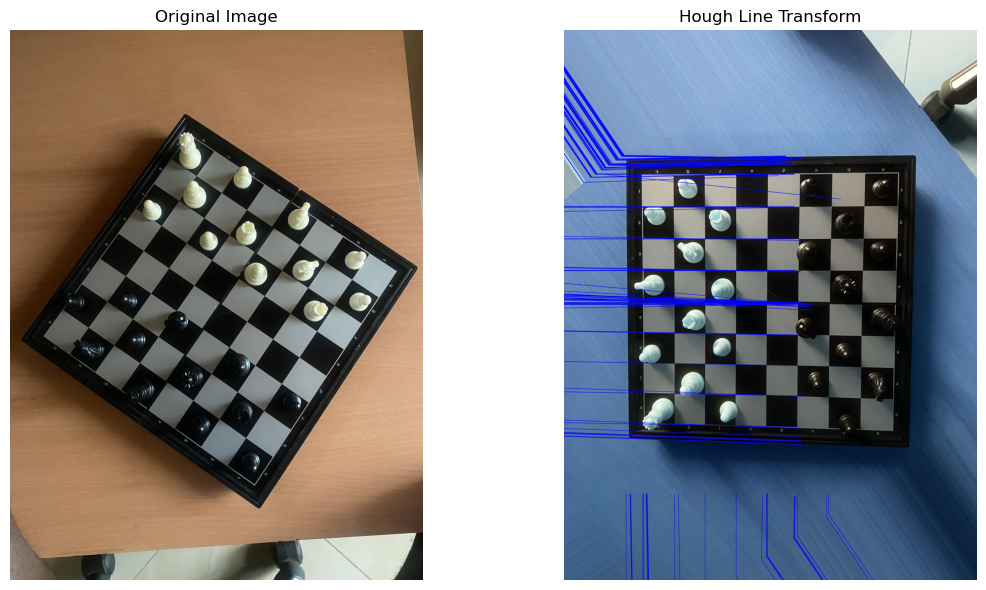

In [55]:
def rotate_image(image, angle):
    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)
    
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, rotation_matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return rotated
rot_img = rotate_image(img, angle)
#show rot_img
plot(plot_orig,rot_img,"canny_houge")

## Canny & Sobel

In [56]:
def find_lines_sobel(image_path):
    # Load the image using opencv
    img = cv2.imread(image_path)

    # Convert the img to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
   
    # Apply Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    # blurred = cv2.GaussianBlur(gray, (3, 3), 0)  # Experiment: smaller kernel
    # blurred = cv2.GaussianBlur(gray, (7, 7), 0)  # Experiment: stronger smoothing

    # Contrast Enhancement using CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(blurred)

    #  Sobel Experiment  
    #  Compute Sobel gradients in x and y directions
    sobelx = cv2.Sobel(enhanced, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(enhanced, cv2.CV_64F, 0, 1, ksize=3)
    
    #Compute gradient magnitude
    sobel_magnitude = np.sqrt(sobelx**2 + sobely**2)
    
    #Convert to 8-bit image
    sobel_magnitude = np.uint8(255 * sobel_magnitude / np.max(sobel_magnitude))
    
    #Apply threshold to get binary edges
    # _, edges = cv2.threshold(sobel_magnitude, 50, 255, cv2.THRESH_BINARY)

    edges = cv2.Canny(sobel_magnitude, 100, 250)
    
    # Apply Hough Transform to detect lines
    # This returns an array of r and theta values
    lines = cv2.HoughLines(edges, 1, np.pi/180, 300)
    # lines = cv2.HoughLines(edges, 1, np.pi/180, 120)  # Experiment: lower threshold
    # lines = cv2.HoughLines(edges, 1, np.pi/360, 150)  # Experiment: finer angle resolution

    # The below for loop runs till r and theta values
    # are in the range of the 2d array
    angles_count = {}

    if lines is not None:
        for r_theta in lines:
            arr = np.array(r_theta[0], dtype=np.float64)
            
            r, theta = arr

            #Convert Polar Coordinates to Cartesian Coordinates
            a = np.cos(theta)
            b = np.sin(theta)
            x0 = a*r
            y0 = b*r

            #Store the angles in a dictionary to count the number of lines corresponding to that angle
            theta_deg = round(theta * 180 / np.pi)  # Rounded for stability

            if theta_deg in angles_count.keys():
                angles_count[theta_deg] += 1
            else:
                angles_count[theta_deg] = 1

            # Second point needed to draw the line
            x1 = int(x0 + 1000*(-b))
            y1 = int(y0 + 1000*(a))

            x2 = int(x0 - 1000*(-b))
            y2 = int(y0 - 1000*(a))

            # Draw the line on the image
            cv2.line(img, (x1, y1), (x2, y2), (0, 0, 255), 2)

    cv2.imwrite('linesDetected.jpg', img)

    # return the angles_count dictionary
    return angles_count


angles_count = find_lines_sobel('q2_data/2b.jpg')
top_3_angles = sorted(angles_count, key=angles_count.get, reverse=True)[:3]
img = cv2.imread('linesDetected.jpg')

print("Top 3 dominant angles (degrees):", top_3_angles)

Top 3 dominant angles (degrees): [35, 124, 125]


In [57]:
# convert top angle go degrees for rotation
angle = top_3_angles[0] -90
angle

-55

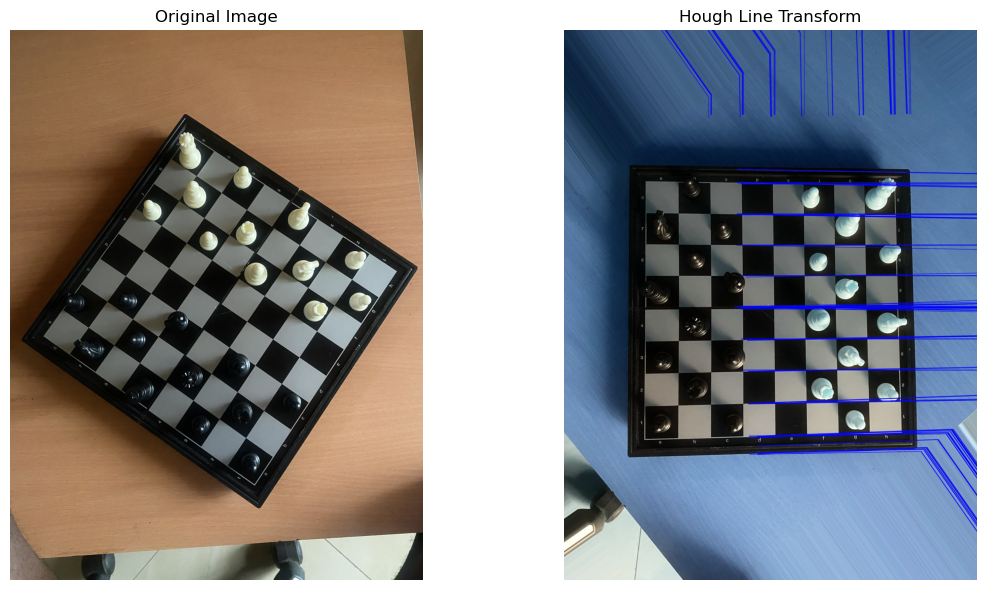

In [58]:
def rotate_image(image, angle):
    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)
    
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, rotation_matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return rotated
rot_img = rotate_image(img, angle)
#show rot_img
plot(plot_orig,rot_img,"sobel_canny")

Top 3 dominant angles (degrees): [17, 20, 19]


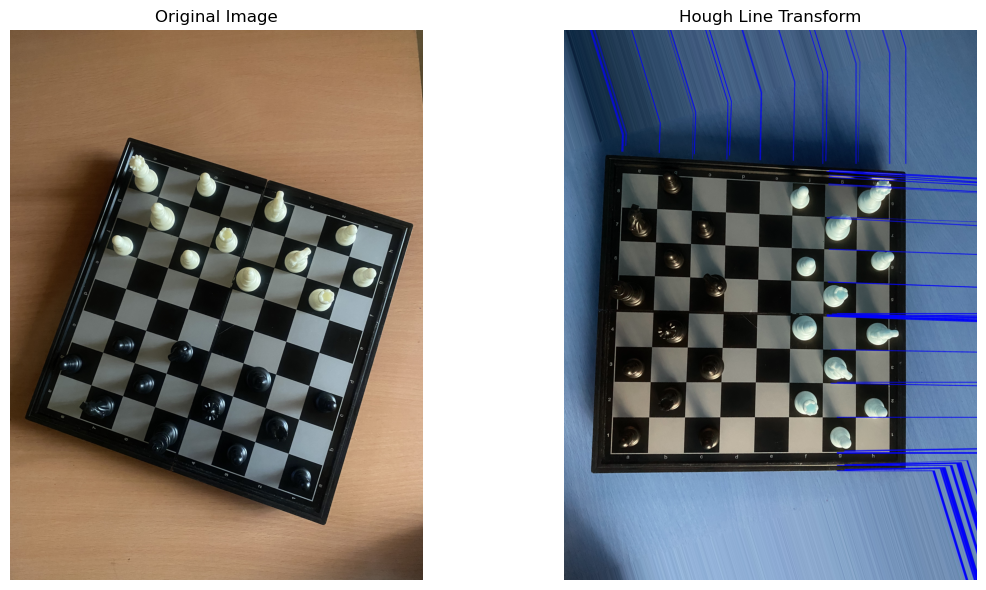

In [59]:
angles_count = find_lines_sobel('q2_data/2c.jpg')
top_3_angles = sorted(angles_count, key=angles_count.get, reverse=True)[:3]
img = cv2.imread('linesDetected.jpg')
c2_im = cv2.imread("q2_data/2c.jpg")
c2_im=cv2.cvtColor(c2_im,cv2.COLOR_BGR2RGB)

angle = top_3_angles[0] -90

print("Top 3 dominant angles (degrees):", top_3_angles)

rot_img = rotate_image(img, angle)
#show rot_img
plot(c2_im,rot_img,"sobel_canny_2c")

Top 3 dominant angles (degrees): [135, 45]


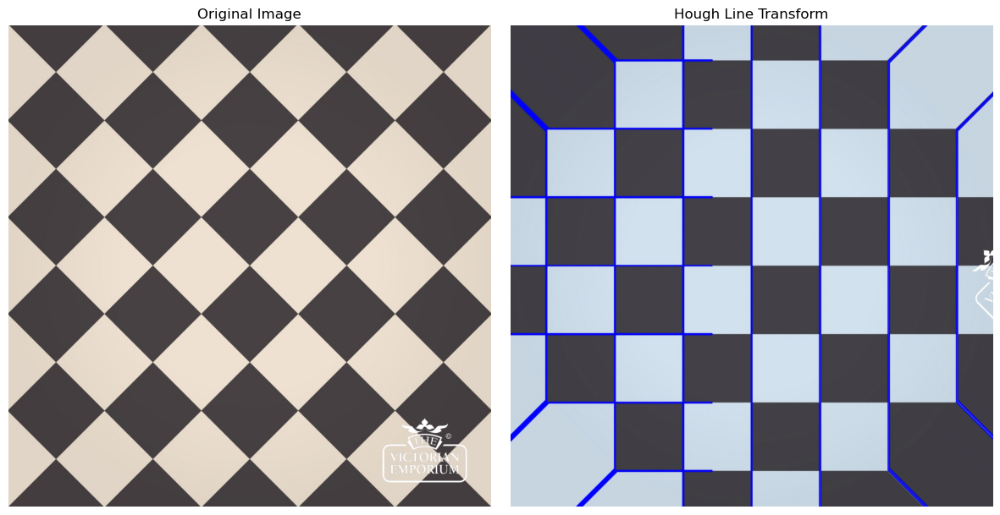

In [150]:
angles_count = find_lines_sobel('tiles.jpg')
top_3_angles = sorted(angles_count, key=angles_count.get, reverse=True)[:3]
img = cv2.imread('linesDetected.jpg')
c2_im = cv2.imread("tiles.jpg")
c2_im=cv2.cvtColor(c2_im,cv2.COLOR_BGR2RGB)

angle = top_3_angles[0] -90

print("Top 3 dominant angles (degrees):", top_3_angles)

rot_img = rotate_image(img, angle)
#show rot_img
plot(c2_im,rot_img,"sobel_canny_tiles_1") #efficient 

Top 3 dominant angles (degrees): [135, 45, 0]


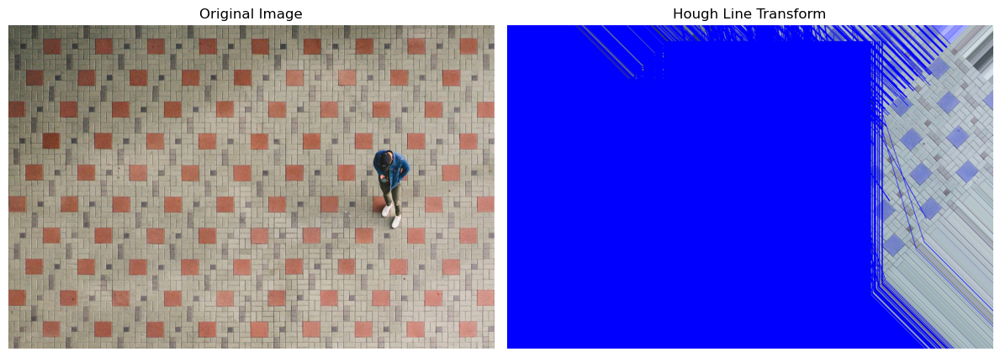

In [61]:
angles_count = find_lines_sobel('trial.jpg')
top_3_angles = sorted(angles_count, key=angles_count.get, reverse=True)[:3]
img = cv2.imread('linesDetected.jpg')
c2_im = cv2.imread("trial.jpg")
c2_im=cv2.cvtColor(c2_im,cv2.COLOR_BGR2RGB)

angle = top_3_angles[0] -90

print("Top 3 dominant angles (degrees):", top_3_angles)

rot_img = rotate_image(img, angle)
#show rot_img
plot(c2_im,rot_img,"sobel_canny_tiles") #many challenges when lines are present 

# Question 3 Image compression

In [62]:
comp_image = cv2.imread("q3_data/q3a.jpg")
comp_gray = cv2.cvtColor(comp_image,cv2.COLOR_BGR2GRAY)

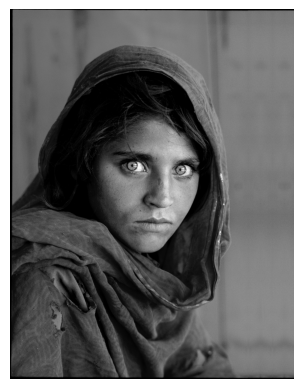

In [63]:
plt.imshow(comp_gray, cmap="gray")
plt.axis("off")
plt.show()

In [64]:
f = np.fft.fft2(comp_gray)
fshift = np.fft.fftshift(f)
magnitude_spectrum = 20* np.log(np.abs(fshift)+1)

In [65]:
magnitude_spectrum

array([[152.63855018, 164.4839438 , 164.16134623, ..., 164.16134623,
        164.4839438 , 152.63855018],
       [173.53652569, 174.81726422, 171.438091  , ..., 120.40090199,
        166.38360036, 172.88775598],
       [162.3071244 , 138.23114531, 144.28816355, ..., 176.52257411,
        177.02277802, 172.43428431],
       ...,
       [169.10716805, 163.90127717, 160.01570841, ..., 169.80043982,
        173.17114916, 151.23931352],
       [172.43428431, 177.02277802, 176.52257411, ..., 144.28816355,
        138.23114531, 162.3071244 ],
       [172.88775598, 166.38360036, 120.40090199, ..., 171.438091  ,
        174.81726422, 173.53652569]])

In [66]:
rows, cols = comp_gray.shape
crow, ccol = rows // 2 , cols // 2

mask = np.zeros((rows, cols), np.uint8)

radius = 50  # experiment with this value

for i in range(rows):
    for j in range(cols):
        if (i - crow)**2 + (j - ccol)**2 <= radius**2:
            mask[i, j] = 1


In [67]:
fshift_comp = fshift * mask 

In [68]:
f_ishift = np.fft.ifftshift(fshift_comp)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)

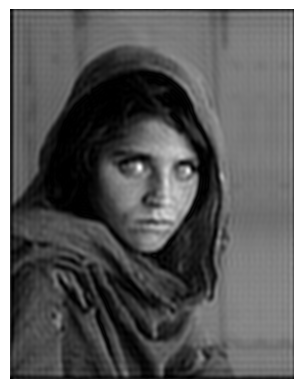

In [69]:
plt.imshow(img_back, cmap="gray")
plt.axis("off")
plt.show()

In [70]:
original_nonzero = np.count_nonzero(fshift)
compressed_nonzero = np.count_nonzero(fshift_comp)

compression_ratio = original_nonzero / compressed_nonzero
print("Compression ratio:", compression_ratio)

Compression ratio: 1111.9648183556405


In [71]:
mse = np.mean((comp_gray - img_back)**2)
print("MSE:", mse)

MSE: 154.97092481000743


In [72]:
low_freq_img = cv2.GaussianBlur(comp_gray, (15,15), 0)

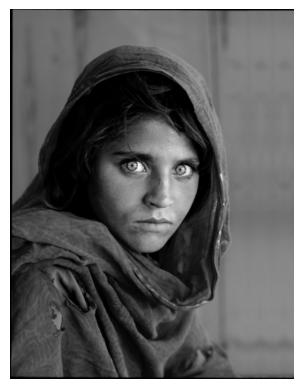

In [73]:
plt.imshow(low_freq_img, cmap="gray")
plt.axis("off")
plt.show()

In [74]:
high_freq_img = cv2.Laplacian(comp_gray, cv2.CV_64F)
high_freq_img = np.uint8(np.absolute(high_freq_img))

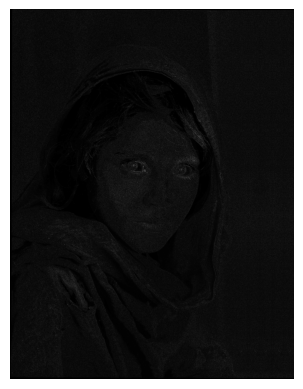

In [75]:
plt.imshow(high_freq_img, cmap="gray")
plt.axis("off")
plt.show()

# Full Algorithm pipeline 

In [76]:
def compress_image(image_path, compress_ratio):
    # Load image using imread
    img = cv2.imread(image_path)

    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Use numpy to get the fast fourier transform of the grayscale image
    computed_fourier = np.fft.fft2(gray)

    # Sort the absolute value of  the frequencies. You will have to flatten the frequencies => fSorted
    fAbs = np.abs(computed_fourier)
    fFlatten = fAbs.flatten()
    fSorted = np.sort(fFlatten)

    # Determine the threshold to keep using thresh = fSorted[int(np.floor((1-compress_ration)*len(fSorted)))]
    thresh = fSorted[int(np.floor((1 - compress_ratio) * len(fSorted)))]

    # create a mask to help filter. mask = np.abs(computed_fourier) >  thresh
    mask = np.abs(computed_fourier) > thresh

    # filter the Fourier using the mask filtered = computer_fourier * mask
    filtered = computed_fourier * mask

    # apply inverse fourier to get a compressed version of the image
    reconstructed = np.fft.ifft2(filtered)
    reconstructed = np.abs(reconstructed)

    reconstructed = np.clip(reconstructed, 0, 255)
    reconstructed = reconstructed.astype(np.uint8)


    # return the image obtained.
    return reconstructed, mask


### Compression Perfomance Metrics

In [77]:
def compute_mse(original, compressed): # mean squared error 
    return np.mean((original - compressed) ** 2)

In [78]:
def compute_psnr(original, compressed):
    mse = compute_mse(original, compressed)
    if mse == 0:
        return 100
    return 20 * np.log10(255 / np.sqrt(mse))

In [79]:
def compression_percentage(mask): #compression percentage 
    kept = np.count_nonzero(mask)
    total = mask.size
    return (kept / total) * 100


In [80]:
def compare_compression_perfomance(image_path,compression_ratio):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Create low and high frequency versions
    low_freq = cv2.GaussianBlur(gray, (21,21), 0)
    
    high_freq = cv2.Laplacian(gray, cv2.CV_64F)
    high_freq = np.uint8(np.absolute(high_freq))
    
    # Compress both
    low_compressed, low_mask = compress_image(image_path, compression_ratio)
    high_compressed, high_mask = compress_image(image_path, compression_ratio)
    
    # Compute metrics
    low_mse = compute_mse(low_freq, low_compressed)
    high_mse = compute_mse(high_freq, high_compressed)
    
    low_psnr = compute_psnr(low_freq, low_compressed)
    high_psnr = compute_psnr(high_freq, high_compressed)
    
    low_keep = compression_percentage(low_mask)
    high_keep = compression_percentage(high_mask)
    
    print("Low Frequency Image:")
    print("MSE:", low_mse)
    print("PSNR:", low_psnr)
    print("Frequencies Kept (%):", low_keep)
    
    print("\nHigh Frequency Image:")
    print("MSE:", high_mse)
    print("PSNR:", high_psnr)
    print("Frequencies Kept (%):", high_keep)
    

Low Frequency Image:
MSE: 8.190290122021734
PSNR: 38.99781074960789
Frequencies Kept (%): 0.9999926633807783

High Frequency Image:
MSE: 92.78972458331442
PSNR: 28.455804752077295
Frequencies Kept (%): 0.9999926633807783


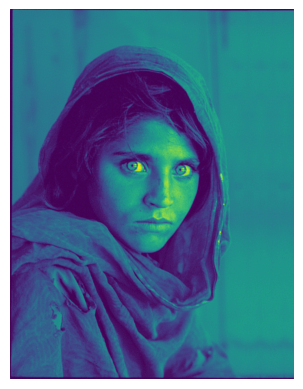

In [81]:
compressed_img,_  =  compress_image("q3_data/q3a.jpg",0.01)
compare_compression_perfomance("q3_data/q3a.jpg",0.01)
plt.imshow(compressed_img)
plt.axis("off")
plt.savefig("image_a_001")
plt.show()

Low Frequency Image:
MSE: 22.12241217952157
PSNR: 34.68247881131285
Frequencies Kept (%): 0.09999582729781767

High Frequency Image:
MSE: 94.62610123800864
PSNR: 28.370694141055417
Frequencies Kept (%): 0.09999582729781767


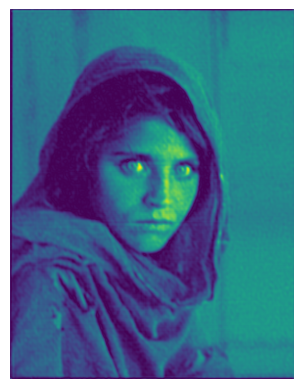

In [82]:
compressed_img, _ =  compress_image("q3_data/q3a.jpg",0.001)
compare_compression_perfomance("q3_data/q3a.jpg",0.001)
plt.imshow(compressed_img)
plt.axis("off")
plt.savefig("image_a_0001")
plt.show()

Low Frequency Image:
MSE: 91.554912109375
PSNR: 28.51398710812751
Frequencies Kept (%): 9.999755859375

High Frequency Image:
MSE: 106.10351806640625
PSNR: 27.873505768582092
Frequencies Kept (%): 9.999755859375


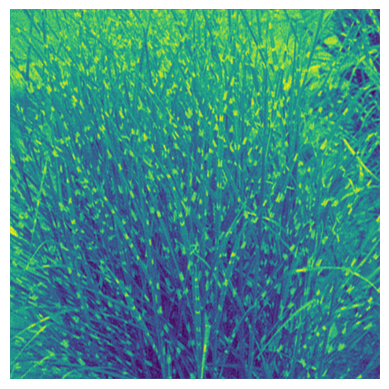

In [83]:
compressed_img,_ =  compress_image("q3_data/q3b.jpg",0.1)
compare_compression_perfomance("q3_data/q3b.jpg",0.1)
plt.imshow(compressed_img)
plt.axis("off")
plt.show()

Low Frequency Image:
MSE: 77.2673046875
PSNR: 29.250845978368304
Frequencies Kept (%): 0.9997558593750001

High Frequency Image:
MSE: 105.96905029296875
PSNR: 27.879013187129967
Frequencies Kept (%): 0.9997558593750001


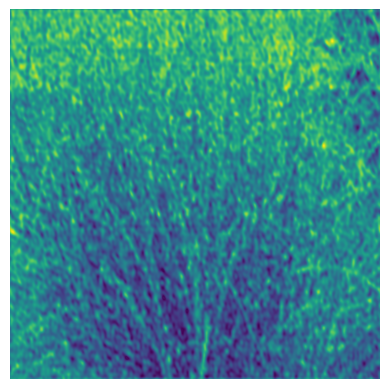

In [84]:
compressed_img,_ =  compress_image("q3_data/q3b.jpg",0.01)
compare_compression_perfomance("q3_data/q3b.jpg",0.01)
plt.imshow(compressed_img)
plt.axis("off")
plt.show()

# High resolution satellite image

In [85]:
satellite = cv2.imread("satellite.jpg")
satellite_gray = cv2.cvtColor(satellite,cv2.COLOR_BGR2GRAY)

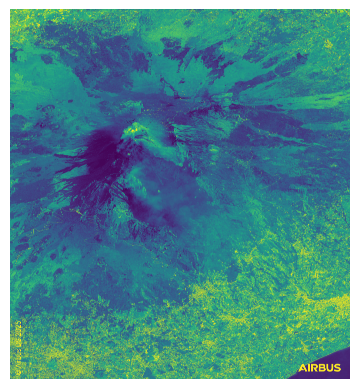

In [86]:
plt.imshow(satellite_gray)
plt.axis("off")
plt.show()

Low Frequency Image:
MSE: 66.83981272315462
PSNR: 29.880451364839967
Frequencies Kept (%): 0.9999995869206977

High Frequency Image:
MSE: 104.60495383517511
PSNR: 27.935281087234912
Frequencies Kept (%): 0.9999995869206977


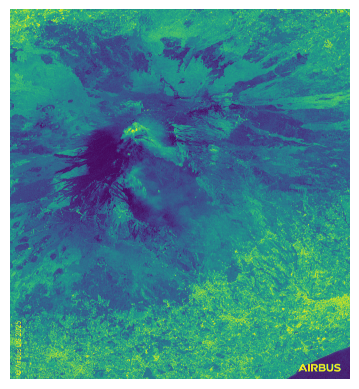

In [87]:
compressed_img,_ =  compress_image("satellite.jpg",0.01)
compare_compression_perfomance("satellite.jpg",0.01)
plt.imshow(compressed_img)
plt.axis("off")
plt.savefig("satellite_001")
plt.show()

Low Frequency Image:
MSE: 75.8341783673674
PSNR: 29.332153751451237
Frequencies Kept (%): 0.009999961445931776

High Frequency Image:
MSE: 104.41398149055902
PSNR: 27.943217043698564
Frequencies Kept (%): 0.009999961445931776


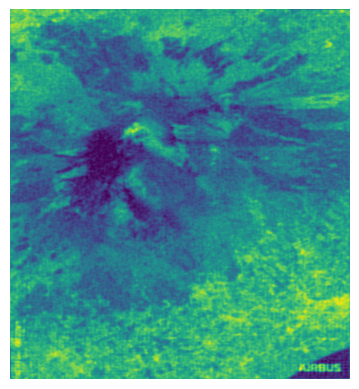

In [88]:
compressed_img,_  =  compress_image("satellite.jpg",0.0001)
compare_compression_perfomance("satellite.jpg",0.0001)
plt.imshow(compressed_img)
plt.axis("off")
plt.savefig("satellite_00001")
plt.show()

### Question 4 Data Augmentation

In [134]:
import cv2
import numpy as np

## Use your own images to test.
def data_augmentation(img, type):

    if type=="resize1":
        # resize the  image to 224 x 224 use nearest neighbor 
        return cv2.resize(img, (224, 224), interpolation=cv2.INTER_NEAREST)

    elif type=="resize2":
        # resize the  image to 224 x 224 use cubic spline interpolation
        return cv2.resize(img, (224, 224), interpolation=cv2.INTER_CUBIC)

    elif type=="vertical_flip":
        # flip the image vertically
        return cv2.flip(img, 0)

    elif type=="horizontal_flip":
        # flip the image horizontally
        return cv2.flip(img, 1)

    elif type=="blur_noise":
        # flip the image horizontally
        # Apply Gaussian blur
        blurred = cv2.GaussianBlur(img, (5,5), 0)

        # Add Gaussian noise
        noise = np.random.normal(0, 10, img.shape).astype(np.uint8)
        noisy = cv2.add(blurred, noise)

        return noisy

    elif type=="rotation":
        # use your own parameters
        angle = 15  # small realistic face tilt
        h, w = img.shape[:2]
        center = (w//2, h//2)

        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        return cv2.warpAffine(img, M, (w, h))

    elif type=="shear on x-axis":
        h, w = img.shape[:2]
        shear_factor = 0.2
    
        # New width after shear
        new_w = int(w + abs(shear_factor) * h)
    
        M = np.float32([
            [1, shear_factor, -shear_factor*h/2],
            [0, 1, 0]
        ])
    
        return cv2.warpAffine(img, M, (new_w, h))

    elif type=="shear on y-axis":
        h, w = img.shape[:2]
        shear_factor = 0.2
    
        # New height after shear
        new_h = int(h + abs(shear_factor) * w)
    
        M = np.float32([
            [1, 0, 0],
            [shear_factor, 1, -shear_factor*w/2]
        ])
    
        return cv2.warpAffine(img, M, (w, new_h))
        
    elif type=="brightness":
        value = 10
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv[:,:,2] = np.clip(hsv[:,:,2] + value, 0, 255)
        return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    elif type=="random_crop":
        h, w = img.shape[:2]
        crop_size = int(0.8 * min(h, w))
    
        start_x = np.random.randint(0, w - crop_size)
        start_y = np.random.randint(0, h - crop_size)
    
        crop = img[start_y:start_y+crop_size, start_x:start_x+crop_size]
        return cv2.resize(crop, (w, h))

    else:
        return img


In [135]:
tulips = cv2.imread("tulips.jpeg")
tulip_rgb = cv2.cvtColor(tulips, cv2.COLOR_BGR2RGB)

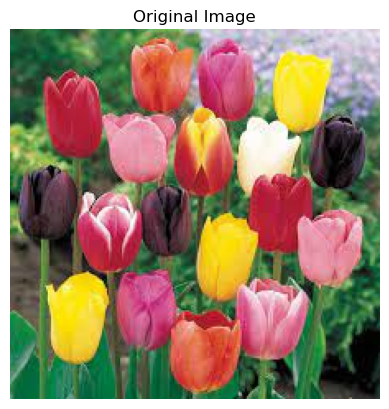

In [136]:
plt.imshow(tulip_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [143]:
import matplotlib.pyplot as plt
import cv2

def plot_augmentations(img_path):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    transforms = [
        "resize1",
        "resize2",
        "vertical_flip",
        "horizontal_flip",
        "blur_noise",
        "rotation",
        "shear on x-axis",
        "shear on y-axis",
        "brightness",
        "random_crop"
    ]

    plt.figure(figsize=(12, 10))

    for i, t in enumerate(transforms):
        aug = data_augmentation(img.copy(), t)

        # Convert BGR → RGB if still 3-channel
        if len(aug.shape) == 3:
            aug = cv2.cvtColor(aug, cv2.COLOR_BGR2RGB)

        plt.subplot(3, 4, i+1)
        plt.imshow(aug)
        plt.title(t)
        plt.axis("off")

    # Original image in last slot
    plt.subplot(3, 4, len(transforms)+1)
    plt.imshow(img_rgb)
    plt.title("original")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


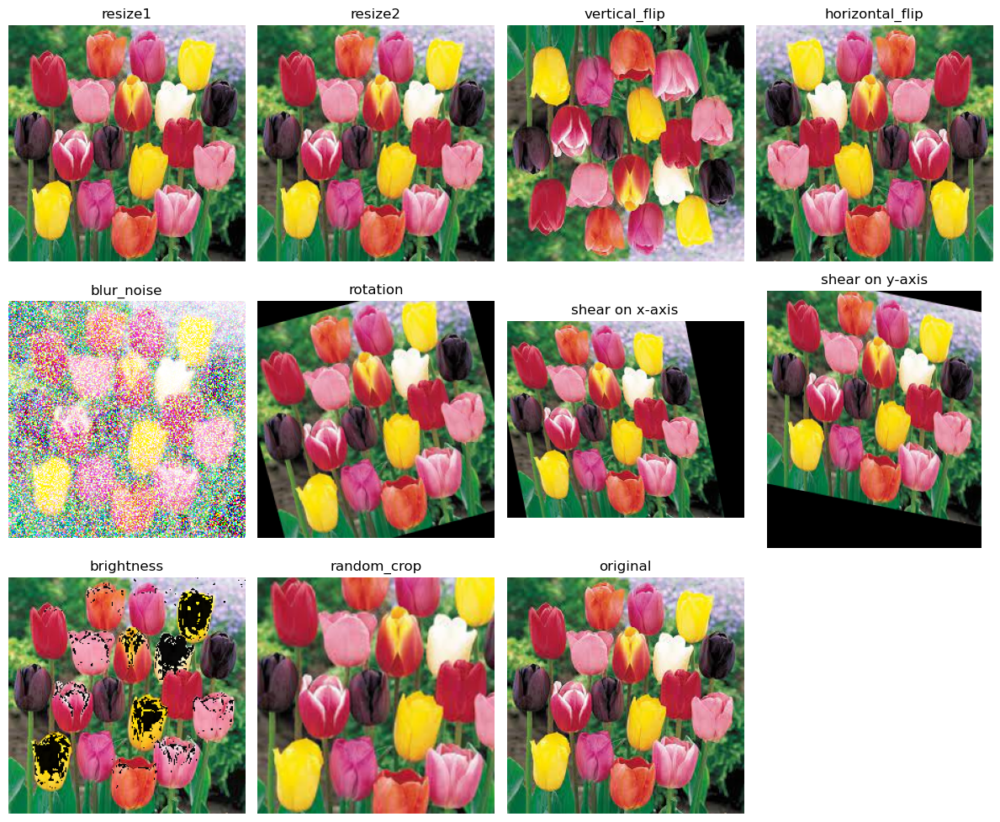

In [146]:
plot_augmentations("tulips.jpeg")

In [149]:

def save_all_augmentations(image_path, output_folder="augmented_images"):

    # Create folder if it does not exist
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    # Load original image
    img = cv2.imread(image_path)

    if img is None:
        print("Error: Image not found.")
        return

    # Save original
    cv2.imwrite(os.path.join(output_folder, "original.jpg"), img)

    # List of augmentations
    augmentations = [
        "resize1",
        "resize2",
        "horizontal_flip",
        "vertical_flip",
        "blur_noise",
        "rotation",
        "shear_x",
        "shear_y",
        "brightness",
        "random_crop"
    ]

    # Apply and save each augmentation
    for aug in augmentations:
        transformed = data_augmentation(img, aug)
        filename = f"{aug}.jpg"
        cv2.imwrite(os.path.join(output_folder, filename), transformed)

    print("All augmented images saved successfully.")




image_path = "tulips.jpeg"  
save_all_augmentations(image_path)

All augmented images saved successfully.
